In [31]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))

# Now import Model from freeflux

import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import analysis.io_func as io_func
from matplotlib import ticker
## notebook where we just load previously generated csv (sampled data + weights) and plot the global flux range (va + sampling)


In [32]:
import pta

In [33]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [34]:
from analysis import config_pta as cfp
 ##flux bounds  
cond='WT'

prep=cfp.config_prep(cond)

removing ['Galkin', 'Gal7', 'Gal10', 'Mankin', 'M6pism', 'MALTGD', 'gal-D_EX', 'man-D_EX', 'malt_EX', 'GALt+0', 'Mant+0', 'MALTt+1']
no met data for ppi_c 'ppi'
no met data for 4pasp_c '4pasp'
no met data for oaa_c 'oaa'
no met data for oaa_m 'oaa'
no met data for nadph_c 'nadph'
no met data for aspsa_c 'aspsa'
no met data for pi_c 'pi'
no met data for pyr_c 'pyr'
no met data for pyr_m 'pyr'
no met data for glycogen_c 'glycogen'
no met data for g1p_c 'g1p'
no met data for glx_c 'glx'
no met data for hco3_m 'hco3'
nadph_m ignored because we set constraint on redox ratio
no met data for hco3_c 'hco3'
no met data for acglu_m 'acglu'
no met data for acg5p_m 'acg5p'
no met data for acg5sa_m 'acg5sa'
no met data for acorn_m 'acorn'
no met data for argsuc_c 'argsuc'
no met data for arg-L_c 'arg-L'
no met data for citr-L_c 'citr-L'
no met data for cbp_c 'cbp'
no met data for glu5p_c 'glu5p'
no met data for pi_m 'pi'
no met data for 10fthf_c '10fthf'
no met data for thf_c 'thf'
no met data for 

## notebook where we just load previously generated csv (sampled data + weights) and plot the distributions
# also plot % unknown rxn 

### In the previous notebooks, we got samples from the flux space that are feasible in the thermodynamically-stoichio constrained drG space (using bounds from VA on drG)
### Here, we get the samples and the sector volumes then plot flux distribution 
### With this we visualize the flux space

## load files for both condition

In [35]:
samples=pd.read_csv(f'{cfp.RESULTS_FOLDER}/b3_flux_sampling/{cond}/{cond}fluxsamples.csv',index_col=0)

In [20]:
## funcitons cell
def plot_VAbounds(axs,rid,axe_index,condition,linewidth=1):
    lb,ub=prep.data_bounds_flux.loc[rid].values
    color=sns.color_palette(palette)[4] if condition=='WT' else sns.color_palette(palette)[5]
    axs[axe_index].axvline(lb, color=color, linewidth=linewidth)
    axs[axe_index].axvline(ub, color=color, linewidth=linewidth)
    return lb,ub

    
def normalize_plotdistr(axs,total_marginals,rxn_index,i,weights=None,label=None,nbins=20):
        counts, bins = np.histogram(total_marginals.T[rxn_index], bins=20,weights=weights)
        counts = counts / counts.sum()
        color=sns.color_palette(palette)[0] if cond=='WT' else sns.color_palette(palette)[2]

        axs[i].bar( 
            bins[:-1], counts, width=np.diff(bins), 
            edgecolor=color,#'black',
            label=label, align='edge',color=color
        )
        axs[i].set_title(prep.model.reactions[rxn_index].id,loc='left',fontsize=12.5)
        return counts,bins

In [21]:
## for the figure we will sort the reactions by ascending order of va flux bounds
##sort for one condition then get like 5/10 reactions evenly spaced and we will plot those with both distributions and both VA bounds
tmpdf=prep.data_bounds_flux.copy()
tmpdf['range']=tmpdf['ub']-tmpdf['lb']
tmpdf=tmpdf.sort_values(by='range',ascending=True)
tmpdf=tmpdf[tmpdf['range']>0]
##get 5 evenly spaced reactions
## or log spaced
n_reactions=5

# step=tmpdf.shape[0]//n_reactions
# r_ids=tmpdf.index[::step]
# Create non-linear spacing (e.g., logarithmic or geometric)
# This creates indices that are denser at the start and more spread out later
spacing_factors = np.logspace(0, 1, n_reactions, base=10)  # Logarithmic from 10^0 to 10^1
spacing_factors = spacing_factors / spacing_factors.sum()  # Normalize to sum to 1
cumulative_indices = np.cumsum(spacing_factors)  # Cumulative sum to get increasing positions
reaction_indices = (cumulative_indices * len(tmpdf)-1).astype(int)  # Scale to total reactions
reaction_indices = np.unique(reaction_indices)  # Remove duplicates (just in case)

# chosen_index=[prep.model.reactions.index(prep.model.reactions.get_by_id(r)) for r in reaction_indices]
len(reaction_indices)


reaction_ids=tmpdf.iloc[reaction_indices].index
# reaction_indices=[mapping_old_new_prep[r] for r in reaction_indices]

In [22]:
reaction_ids

Index(['ANS', 'umpSYN', 'IPPMIb', 'GHMT2', 'ampSYN2'], dtype='object')

In [23]:
## plt rc params 
plt.rcParams['axes.spines.left'] = False
plt.rcParams['ytick.left'] = False
plt.rcParams['ytick.labelleft'] = False
# plt.rcParams['xtick.bottom'] = False
# plt.rcParams['xtick.labelbottom'] = False

colormain= palette[0] if cond=='WT' else palette[2]
colorfill= palette[1] if cond=='WT' else palette[3]

In [24]:
from matplotlib.ticker import FormatStrFormatter

(0.0, 1.405932913114524)


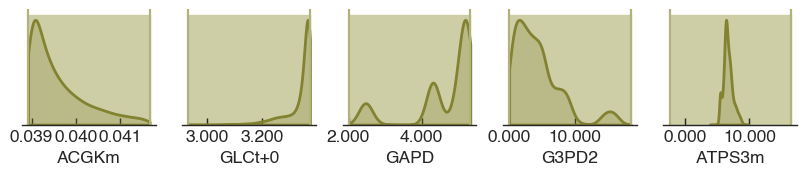

In [30]:
##first WT
fig, axs = plt.subplots(1,5,figsize=(10,1.5))#,layout='tight')
axs=axs.flatten()
io_func.scale_rcparams(fig,scalingf=0.5)
plt.rcParams['xtick.labelsize']=12.5
reaction_ids=[prep.model.reactions.get_by_id('ACGKm').id,prep.model.reactions.get_by_id('GLCt+0').id, ## WT
                  prep.model.reactions.get_by_id('GAPD').id,prep.model.reactions.get_by_id('G3PD2').id,
                  #,prep.model.reactions.get_by_id('PPCK').id,prep.model.reactions.get_by_id('ICDHym').id,
                  prep.model.reactions.get_by_id('ATPS3m').id]#,prep.model.reactions.get_by_id('G3PD2').id]
# do with reaction id 'lipids_reaction', 'GLCt+0',       'GAPD', 'G3PD2',
# reaction_ids=[prep.model.reactions.get_by_id('ACGKm').id,prep.model.reactions.get_by_id('GLCt+0').id,
#                   prep.model.reactions.get_by_id('GAPD').id,prep.model.reactions.get_by_id('G3PD2').id,
#                   #,prep.model.reactions.get_by_id('PPCK').id,prep.model.reactions.get_by_id('ICDHym').id,
#                   prep.model.reactions.get_by_id('ATPS3m').id]#,prep.model.reactions.get_by_id('G3PD2').id]
# reaction_ids=np.random.choice(samples.columns, size=5, replace=False)
# reaction_ids=[prep.model.reactions[i].id for i in reaction_indices] 
def rescale_ylim(ax):## just great
    yticks = ax.get_yticks()
    ax.set_yticks(np.linspace(yticks[0], yticks[-1], 3))
    return ax

for i,rxn_id in enumerate(reaction_ids):
    # counts_w,bins_weighted = normalize_plotdistr(axs,samples_wt1.T,rxn_index,i=i,weights=None,label='Weighted distribution WT',nbins=int(5*(i//6+1)))
    #plot va bounds as vertical lines
    lb,ub=plot_VAbounds(axs,rxn_id,i,cond,linewidth=4/2.5)
    sns.kdeplot(samples[rxn_id],ax=axs[i],color= colormain,label=cond,linewidth=2,bw_adjust=2,fill=True,clip=[lb,ub])
    axs[i].locator_params(axis='x', nbins=3)
    axs[i].locator_params(axis='y', nbins=3)
    ymin,ymax=axs[i].get_ylim()
    # print(ymin,ymax,lb,ub)
    axs[i].fill_between([lb, ub], ymin, ymax, color=colorfill, zorder=-103)
    # io_func.rescale_axlim(axs[i],how='x',nbins=)
    # io_func.rescale_axlim(axs[i],how='x',nbins=4)
    ##format xticks to have 1 decimals
    axs[i].xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
    axs[i].set_yticks([])
    # axs[i].set_title(rxn_id,fontsize=12.5)
# 

# axs[0].set_xlim(-0.5,0)
# axs[1].set_xlim(axs[1].get_xlim()[0],14.5)#,axs[1].set_ylim(0,0.2)
# io_func.rescale_axlim(axs[i])
##function to rescale ylim to have only 3 ticks

print(axs[2].get_ylim())
# rescale_ylim(axs[2])

# # ### save fig 
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig4f_{cond}_kdeplots_sampling.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig4f_{cond}_kdeplots_sampling.svg',dpi=300,bbox_inches='tight')


### compare stoichiometric samples with samples from PTA

In [ ]:
### in notebook 0a_tm6 we had genereated flux samples from stoichiometric model only 
stoichio_samples=pd.read_csv(f'{cfp.RESULTS_FOLDER}..//a_fluxspace/TM6_stoichio_fluxsamples_wbounds.csv',index_col=0).loc[samples.columns].T
stoichio_samples

,ASNS1,ASPK,ASPTA,ASPTAm,ASAD,ALATA_L,ALATA_Lm,GLCS2,PGMT,GALU,...,PItm-2+2H,PItm-2+H,PItm-2,PYRtm-1,PYRtm-1+H,SUCCPItm-2-2,SUCFUMtm-2-2,THRtm+0,biomass_ce,biomass_EX
0,0.024679,0.351259,3.570354,-4.136225,0.351259,130.847823,-130.166772,0.007914,-0.058681,0.035139,...,0.254069,133.813763,-0.540195,3.032359,-126.407216,-41.717263,40.136644,0.045160,0.242664,0.242664
1,0.024854,0.285457,-0.592385,0.090792,0.285457,118.744096,-117.910263,0.136760,-0.442609,0.547690,...,5.418259,130.684810,-0.873811,4.170903,-115.921021,-28.816989,27.699817,0.045480,0.244387,0.244387
2,0.025096,0.648707,-25.883448,25.016503,0.648707,57.304394,-55.422077,0.090886,-1.017645,1.076544,...,29.428641,91.552299,-9.502076,22.723822,-68.711468,45.875465,-44.159080,0.045923,0.246764,0.246764
3,0.025722,2.581421,22.524788,-25.329889,2.581421,63.170400,-63.852873,0.481606,-2.186913,2.635735,...,29.411598,68.044503,-4.736694,9.340056,-62.216156,56.639383,-64.004898,0.047068,0.252917,0.252917
4,0.025627,0.377565,-2.405729,1.805305,0.377565,29.109650,-29.267235,0.467686,-2.532912,2.967934,...,26.046150,56.500229,-1.970397,16.227209,-27.903877,77.883349,-83.854828,0.046895,0.251989,0.251989
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10003,0.025934,1.049251,2.199131,-3.473911,1.049251,-14.667318,16.680185,0.073152,-4.261809,4.301906,...,18.753740,23.075818,-3.375392,32.349013,11.144288,79.204777,-81.512976,0.047457,0.255008,0.255008
10004,0.025819,1.207775,9.669976,-11.102282,1.207775,-1.676898,2.390545,0.201827,-4.473526,4.642444,...,18.844567,25.372302,-0.277422,31.418745,-3.116471,70.024147,-75.296574,0.047247,0.253879,0.253879
10005,0.025940,1.093371,-3.713919,2.394971,1.093371,-11.127023,11.769794,0.164065,-4.474461,4.605464,...,26.913094,24.028864,-6.256288,28.852565,1.313783,59.078800,-64.666014,0.047467,0.255061,0.255061
10006,0.025850,0.844786,-3.476378,2.406793,0.844786,-14.233624,16.054330,0.417307,-5.610029,5.994387,...,13.146886,41.744816,-2.531301,27.908182,0.316796,65.288465,-71.077993,0.047303,0.254182,0.254182


SUCFUMtm-2-2    270.144501
ETOHtm+0        166.286054
ORNtm+1         134.770952
MEm             112.687607
Name: range, dtype: float64


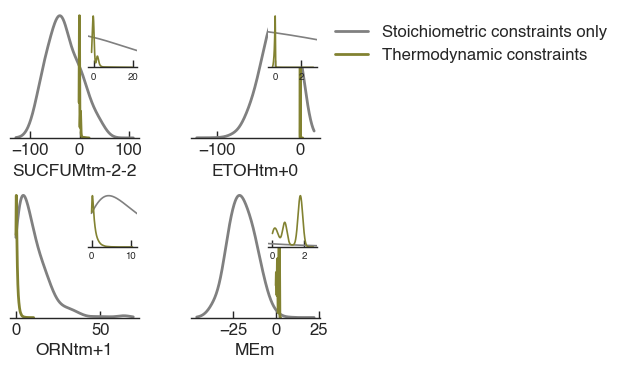

In [ ]:
from scipy.stats import gaussian_kde

## select reactions: widest VA range first, then every 5th reaction
tmpdf = prep.data_bounds_flux.copy()
tmpdf['range'] = tmpdf['ub'] - tmpdf['lb']
tmpdf = tmpdf[tmpdf['range'] > 0]
tmpdf = tmpdf.sort_values(by='range', ascending=False)
tmpdf = tmpdf[tmpdf.index.isin(samples.columns) & tmpdf.index.isin(stoichio_samples.columns)]

n_reactions = 4
step = 15
# reaction_ids = tmpdf.index[::step][:n_reactions]
reaction_ids=['SUCFUMtm-2-2','ETOHtm+0','ORNtm+1','MEm']
print(tmpdf.loc[reaction_ids, 'range'])

def peak_normalized_kde(x, bw_adjust=2, clip=None, n=500):
    """KDE evaluated on a grid and scaled so its maximum is 1."""
    x = np.asarray(x)
    lo, hi = clip if clip is not None else (x.min(), x.max())
    if np.isclose(x.std(), 0) or np.isclose(lo, hi):   # all samples identical
        return np.array([x.mean()] * 2), np.array([0, 1])
    kde = gaussian_kde(x, bw_method=lambda k: k.scotts_factor() * bw_adjust)
    grid = np.linspace(lo, hi, n)
    dens = kde(grid)
    return grid, dens / dens.max()

## overlay thermodynamic vs stoichiometric sampling
fig, axs = plt.subplots(2, 2, figsize=(4, 4))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
axs = axs.flatten()
io_func.scale_rcparams(fig, scalingf=0.5)
plt.rcParams['xtick.labelsize'] = 12

color_stoich = 'grey'
show_inset = True   # zoom on the cond range

for i, rxn_id in enumerate(reaction_ids):

    xs = stoichio_samples[rxn_id]
    xt = samples[rxn_id]
    gs, ds = peak_normalized_kde(xs)
    gt, dt = peak_normalized_kde(xt, clip=(max(lb, xt.min()), min(ub, xt.max())))

    axs[i].plot(gs, ds, color=color_stoich, lw=2, label='Stoichiometric constraints only')
    axs[i].plot(gt, dt, color=colormain, lw=2, label='Thermodynamic constraints')
    axs[i].set_ylim(0, 1.05)

    axs[i].locator_params(axis='x', nbins=3)
    axs[i].set_yticks([])
    axs[i].set_ylabel('')
    axs[i].set_xlabel(rxn_id)

    if show_inset:
        ins = axs[i].inset_axes([0.6, 0.55, 0.38, 0.42])
        pad = 0.1 * (gt.max() - gt.min() + 1e-9)
        ins.plot(gs, ds, color=color_stoich, lw=1.2)
        ins.plot(gt, dt, color=colormain, lw=1.2)
        ins.set_xlim(gt.min() - pad, gt.max() + pad)
        ins.set_ylim(0, 1.05)
        ins.set_yticks([])
        ins.locator_params(axis='x', nbins=2)
        ins.tick_params(labelsize=7)

axs[1].legend(frameon=False, fontsize=12, loc='upper left', bbox_to_anchor=(1, 1))

# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig_{cond}_samples_stoichiovthermo_overlay.png', dpi=300, bbox_inches='tight')
# plt.savefig(f'{cfp.PLOTS_FOLDER}/fig_{cond}_samples_stoichiovthermo_overlay.svg', dpi=300, bbox_inches='tight')